# Distributions and outliers of the hotel bookings dataset

**Data source:** Antonio, N., de Almeida, A. and Nunes, L. (2019). *Hotel booking demand datasets*. Data in Brief, 22, 41–49. https://doi.org/10.1016/j.dib.2018.11.126 (file `hotel_bookings_dataset.csv`).
**Date:** 2026-11-04
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** This notebook explores how the values of each field are distributed and which values are outliers (Part 1, task 1.3), with several exploratory charts. It uses the **raw** data: the cleaning rules are chosen later, in task 1.6, so the charts show the data as it arrives, problems included.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration: summary statistics and outliers](#2.-Initial-exploration:-summary-statistics-and-outliers)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: shares of the categorical fields](#4.-Analysis:-shares-of-the-categorical-fields)
5. [Accessible visualisation: exploratory charts](#5.-Accessible-visualisation:-exploratory-charts)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
from pathlib import Path

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

RAW_FILE   = Path('../../Course information/hotel_bookings_dataset.csv')
OUTPUT_DIR = Path('distributions_outliers_output')
IMAGES_DIR = Path('../images')
OUTPUT_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

# Common style for every chart (accessible: dark text, one dark colour for data, light grid)
BAR_COLOR    = '#1F4E79'   # dark blue, contrast about 9:1 on white
TEXT_COLOR   = '#1A1A1A'
LABEL_COLOR  = '#595959'   # contrast 7:1 on white
GRID_COLOR   = '#DDDDDD'
FIG_WIDTH    = 6.3         # inches = 16 cm, the text width of the PDF
SOURCE_TEXT  = 'Source: Antonio, de Almeida and Nunes (2019), hotel bookings dataset, raw file (119,390 bookings).'

plt.rcParams.update({'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
                     'axes.edgecolor': LABEL_COLOR, 'xtick.color': LABEL_COLOR, 'ytick.color': LABEL_COLOR,
                     'axes.labelcolor': TEXT_COLOR, 'text.color': TEXT_COLOR})

print('pandas', pd.__version__, '| matplotlib', matplotlib.__version__)

pandas 2.3.3 | matplotlib 3.10.9


In [2]:
# ── Helper functions for the charts ──────────────────────────────────────────

def finish_figure(fig, title, file_name, note=None):
    """Add the figure title, an optional note and the data source, and save the figure in the images folder."""
    fig.suptitle(title, x=0.01, ha='left', fontsize=11, color=TEXT_COLOR)
    # Source on the last line; a note (for example values left out of the chart) on the line above
    line_height = 0.11 / fig.get_figheight()          # about 8 points, as a fraction of the figure
    fig.text(0.01, 0.005, SOURCE_TEXT, fontsize=7, color=LABEL_COLOR)
    if note:
        fig.text(0.01, 0.005 + line_height, note, fontsize=7, color=LABEL_COLOR)
    bottom = (2 if note else 1) * line_height + 0.01
    fig.tight_layout(rect=(0, bottom, 1, 0.97))
    fig.savefig(IMAGES_DIR / file_name, dpi=200)
    return IMAGES_DIR / file_name


def clean_axes(ax, grid_axis='x'):
    """Remove the top and right borders and keep a light grid on the value axis (figure and ground)."""
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID_COLOR, linewidth=0.6)
    ax.set_axisbelow(True)


print('Helpers ready: finish_figure, clean_axes')

Helpers ready: finish_figure, clean_axes


## 1. Data loading

In [3]:
# ── Load ──────────────────────────────────────────────────────────────────────

# Only NA and NULL are treated as missing (see the data quality notebook)
bookings = pd.read_csv(RAW_FILE, keep_default_na=False, na_values=['NA', 'NULL'])
TOTAL_ROWS = len(bookings)

# Two derived fields that are easier to read than their parts
bookings['total_nights'] = bookings['stays_in_weekend_nights'] + bookings['stays_in_week_nights']
bookings['total_guests'] = bookings['adults'] + bookings['children'].fillna(0) + bookings['babies']

print(f'Rows: {TOTAL_ROWS:,} | Columns: {bookings.shape[1]} (32 original + 2 derived)')
bookings[['lead_time', 'adr', 'total_nights', 'total_guests']].head()

Rows: 119,390 | Columns: 34 (32 original + 2 derived)


,lead_time,adr,total_nights,total_guests
0,342,0.0,0,2.0
1,737,0.0,0,2.0
2,7,75.0,1,1.0
3,13,75.0,1,1.0
4,14,98.0,2,2.0


### Decision: two derived fields for exploration

**Context:** the length of a stay is split into weekend and week nights, and the party into adults, children and babies.

**Decision taken:** `total_nights` and `total_guests` are added **only in this notebook**, as sums of existing fields, because a reader thinks in "nights" and "people". The raw file is not changed; whether these fields enter the cleaned data is decided in task 1.6.

> ⚠️ **Limitation:** the 4 `children = NA` are counted as 0 in `total_guests`.

## 2. Initial exploration: summary statistics and outliers

In [4]:
# ── Summary statistics and the 1.5 × IQR rule ────────────────────────────────

numeric_fields = ['lead_time', 'adr', 'total_nights', 'stays_in_weekend_nights', 'stays_in_week_nights',
                  'adults', 'children', 'babies', 'total_guests', 'booking_changes', 'days_in_waiting_list',
                  'total_of_special_requests', 'required_car_parking_spaces',
                  'previous_cancellations', 'previous_bookings_not_canceled']

rows = []
for field in numeric_fields:
    values = bookings[field].dropna()
    q1, median, q3 = values.quantile([0.25, 0.50, 0.75])
    upper_fence = q3 + 1.5 * (q3 - q1)          # Tukey's rule, the one used by box plots
    rows.append({
        'field': field,
        'min': values.min(),
        'q1': q1,
        'median': median,
        'mean': round(values.mean(), 1),
        'q3': q3,
        'max': values.max(),
        'upper fence (q3 + 1.5 IQR)': upper_fence,
        'rows above fence': int((values > upper_fence).sum()),
        '% of rows equal to 0': round(100 * (values == 0).mean(), 1),
        'skewness': round(values.skew(), 1),
    })

distribution_summary = pd.DataFrame(rows).set_index('field')
distribution_summary

,min,q1,median,mean,q3,max,upper fence (q3 + 1.5 IQR),rows above fence,% of rows equal to 0,skewness
field,,,,,,,,,,
lead_time,0.00,18.00,69.000,104.0,160.0,737.0,373.000,3005,5.3,1.3
adr,-6.38,69.29,94.575,101.8,126.0,5400.0,211.065,3793,1.6,10.5
total_nights,0.00,2.00,3.000,3.4,4.0,69.0,7.000,5257,0.6,3.3
stays_in_weekend_nights,0.00,0.00,1.000,0.9,2.0,19.0,5.000,265,43.6,1.4
stays_in_week_nights,0.00,1.00,2.000,2.5,3.0,50.0,6.000,3354,6.4,2.9
adults,0.00,2.00,2.000,1.9,2.0,55.0,2.000,6280,0.3,18.3
children,0.00,0.00,0.000,0.1,0.0,10.0,0.000,8590,92.8,4.1
babies,0.00,0.00,0.000,0.0,0.0,10.0,0.000,917,99.2,24.6
total_guests,0.00,2.00,2.000,2.0,2.0,55.0,2.000,14578,0.2,10.2


### Decision: how outliers are identified

**Context:** an outlier is a value far from the bulk of the data. The usual rule, the one a box plot draws, flags values above Q3 + 1.5 × IQR (interquartile range).

**Decision taken:** the rule is used for `lead_time`, `adr` and `total_nights`, which have a real spread. For the other fields it does not work: Q1 and Q3 are equal (for example both are 2 adults, or both 0 changes), so the IQR is 0 and **every** value different from the typical one becomes an "outlier". For those fields the table shows the share of zeros and the maximum instead, and odd values are judged by meaning (as in the data quality notebook).

**Key findings:** every numeric field is **right-skewed** (skewness > 1): most bookings have small values and a long tail of a few very large ones. Many counts are almost always 0 (for example 96.9 % of bookings never waited in the waiting list).

## 3. Cleaning and preparation

Nothing is cleaned here; the charts show the raw data. Values that are clearly errors (the `adr` of 5,400) are left out of a chart **only when they would squash the scale**, and the chart says so in a note.

## 4. Analysis: shares of the categorical fields

In [5]:
# ── Share of each category ───────────────────────────────────────────────────

categorical_fields = ['hotel', 'reservation_status', 'market_segment', 'distribution_channel',
                      'customer_type', 'deposit_type', 'meal', 'is_repeated_guest']

category_shares = pd.concat({
    field: (100 * bookings[field].value_counts() / TOTAL_ROWS).round(1)
    for field in categorical_fields
}).rename('% of bookings')
category_shares

hotel                 City Hotel         66.4
                      Resort Hotel       33.6
reservation_status    Check-Out          63.0
                      Canceled           36.0
                      No-Show             1.0
market_segment        Online TA          47.3
                      Offline TA/TO      20.3
                      Groups             16.6
                      Direct             10.6
                      Corporate           4.4
                      Complementary       0.6
                      Aviation            0.2
                      Undefined           0.0
distribution_channel  TA/TO              82.0
                      Direct             12.3
                      Corporate           5.6
                      GDS                 0.2
                      Undefined           0.0
customer_type         Transient          75.1
                      Transient-Party    21.0
                      Contract            3.4
                      Group       

In [6]:
# ── Countries ─────────────────────────────────────────────────────────────────

# Shares over ALL bookings, so the missing countries are visible as their own group
country_counts = bookings['country'].fillna('Missing').value_counts()
top_countries = country_counts.drop('Missing').head(10)
other_countries = country_counts.drop(['Missing'] + list(top_countries.index))

country_table = pd.concat([top_countries,
                           pd.Series({f'Other ({len(other_countries)} codes)': other_countries.sum(),
                                      'Missing': country_counts['Missing']})])
country_table = pd.DataFrame({'bookings': country_table,
                              '% of bookings': (100 * country_table / TOTAL_ROWS).round(1)})
country_table

,bookings,% of bookings
PRT,48590,40.7
GBR,12129,10.2
FRA,10415,8.7
ESP,8568,7.2
DEU,7287,6.1
ITA,3766,3.2
IRL,3375,2.8
BEL,2342,2.0
BRA,2224,1.9
NLD,2104,1.8


### Interpretation of the shares

- The **City Hotel** has two thirds of the bookings (66.4 %), so totals mixing both hotels are dominated by it; comparisons between hotels should use rates, not counts.
- **36.0 %** of bookings were cancelled and 1.0 % were no-shows (37.0 % with `is_canceled` = 1).
- Bookings come mostly through intermediaries: `Online TA` is 47.3 % of the market segments and `TA/TO` 82.0 % of the channels.
- Most bookings are `Transient` (75.1 %), have no deposit (87.6 %) and include breakfast only (`BB`, 77.3 %).
- **Portugal** alone is about four in ten bookings (40.7 % of all rows) and the ten main countries make about 84 %; the remaining 167 codes are small, which matters for any map or country ranking (most countries would be almost empty).

## 5. Accessible visualisation: exploratory charts

Every chart follows the same rules: a title that states what is shown, axis labels with units, the data source at the bottom, bars that start at zero, one dark colour (no information is coded by colour alone) and a light grid kept in the background (figure and ground). Chart types follow the course's "charts by data type" (02-HowToApproachAVisualization): a **histogram** for one continuous variable, a **box plot** to compare a distribution between groups, and **bar charts** for discrete and categorical fields.

### Chart 1: lead time

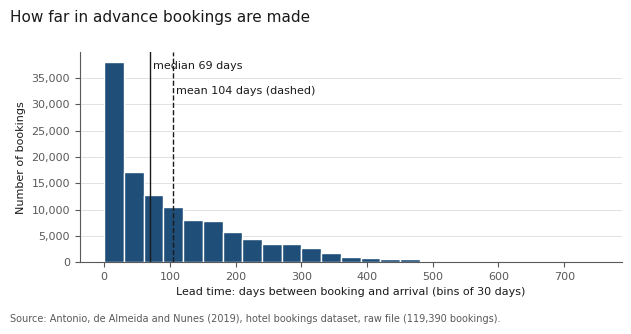

Bookings made 7 days or less before arrival: 16.5 %
Bookings made more than a year before arrival: 2.6 %


In [7]:
# ── Chart 1: histogram of lead time ──────────────────────────────────────────

lead_time_median = bookings['lead_time'].median()
lead_time_mean = bookings['lead_time'].mean()

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.2))
ax.hist(bookings['lead_time'], bins=range(0, 751, 30), color=BAR_COLOR, edgecolor='white')

# Median and mean as labelled lines (labels, not colour, tell them apart)
ax.axvline(lead_time_median, color=TEXT_COLOR, linestyle='-', linewidth=1)
ax.axvline(lead_time_mean, color=TEXT_COLOR, linestyle='--', linewidth=1)
ax.text(lead_time_median + 5, ax.get_ylim()[1] * 0.92, f'median {lead_time_median:.0f} days', fontsize=8)
ax.text(lead_time_mean + 5, ax.get_ylim()[1] * 0.80, f'mean {lead_time_mean:.0f} days (dashed)', fontsize=8)

ax.set_xlabel('Lead time: days between booking and arrival (bins of 30 days)')
ax.set_ylabel('Number of bookings')
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
clean_axes(ax, 'y')
finish_figure(fig, 'How far in advance bookings are made', 'eda_lead_time.png')
plt.show()

print(f"Bookings made 7 days or less before arrival: {100 * (bookings['lead_time'] <= 7).mean():.1f} %")
print(f"Bookings made more than a year before arrival: {100 * (bookings['lead_time'] > 365).mean():.1f} %")

**Comment:** lead time is strongly right-skewed. The median booking is made 69 days before arrival, but the mean is 104 days because of a long tail: 16.5 % of bookings are made in the last week, while 2.6 % are made more than a year ahead (up to 737 days). The 1.5 × IQR rule flags 3,005 bookings above 373 days; they are plausible (early group or tour-operator blocks), not errors. Because the shape is so skewed, the median, not the mean, is the right summary for a dashboard.

### Chart 2: average daily rate by hotel

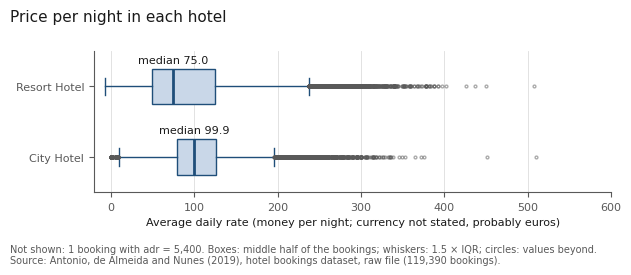

,count,mean,std,min,25%,50%,75%,max
hotel,,,,,,,,
City Hotel,79330.0,105.3,43.6,0.0,79.2,99.9,126.0,5400.0
Resort Hotel,40060.0,95.0,61.4,-6.4,50.0,75.0,125.0,508.0


In [8]:
# ── Chart 2: box plots of adr by hotel ───────────────────────────────────────

# The single adr of 5,400 is left out of this chart only, because it would squash the scale
ADR_LIMIT = 600
hotels = ['City Hotel', 'Resort Hotel']
adr_per_hotel = [bookings.loc[(bookings['hotel'] == h) & (bookings['adr'] < ADR_LIMIT), 'adr'] for h in hotels]
left_out = (bookings['adr'] >= ADR_LIMIT).sum()

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 2.6))
ax.boxplot(adr_per_hotel, vert=False, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor='#C9D7E8', edgecolor=BAR_COLOR),
           medianprops=dict(color=BAR_COLOR, linewidth=2),
           whiskerprops=dict(color=BAR_COLOR), capprops=dict(color=BAR_COLOR),
           flierprops=dict(marker='o', markersize=2, markerfacecolor='none', markeredgecolor=LABEL_COLOR, alpha=0.5))
ax.set_yticks([1, 2], hotels)

# Median written next to each box, so it does not have to be estimated from the drawing
for position, values in enumerate(adr_per_hotel, start=1):
    ax.text(values.median(), position + 0.33, f'median {values.median():.1f}', ha='center', fontsize=8)

ax.set_xlabel('Average daily rate (money per night; currency not stated, probably euros)')
ax.set_xlim(-20, ADR_LIMIT)
clean_axes(ax, 'x')
finish_figure(fig, 'Price per night in each hotel', 'eda_adr_by_hotel.png',
              note=f'Not shown: {left_out} booking with adr = 5,400. Boxes: middle half of the bookings; whiskers: 1.5 × IQR; circles: values beyond.')
plt.show()

bookings.groupby('hotel')['adr'].describe().round(1)

**Comment:** the City Hotel is more expensive in the middle of the distribution (median 99.9 against 75.0) but the Resort Hotel varies much more: its central half goes from 50 to 125, against 79 to 126 in the City Hotel, which suggests a strong season effect (checked in task 1.4). Both hotels have many high values beyond the whiskers (3,793 bookings above the overall fence of 211); values up to about 510 are plausible for a high-season stay, while the 5,400 and the −6.38 are not (see the data quality notebook). For the dashboard, prices should be compared with medians and ranges, not means.

### Chart 3: length of stay

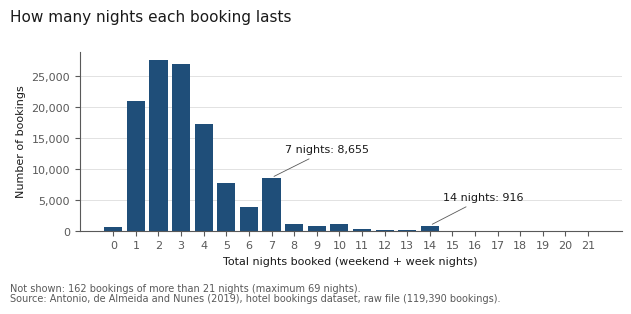

total_nights
5     7784
6     3857
7     8655
8     1161
9      841
10    1139
11     396
12     223
13     142
14     916
15      75
Name: count, dtype: int64

In [9]:
# ── Chart 3: bar chart of total nights ───────────────────────────────────────

# Nights are discrete, so each value gets its own bar (no bins); stays above 21 nights are counted apart
MAX_NIGHTS_SHOWN = 21
nights_counts = bookings['total_nights'].value_counts().sort_index()
shown = nights_counts.loc[:MAX_NIGHTS_SHOWN]
longer = nights_counts.loc[MAX_NIGHTS_SHOWN + 1:].sum()

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.0))
ax.bar(shown.index, shown.values, color=BAR_COLOR, width=0.8)
for nights in [7, 14]:
    ax.annotate(f'{nights} nights: {shown[nights]:,}', xy=(nights, shown[nights]),
                xytext=(nights + 0.6, shown[nights] + 4000), fontsize=8,
                arrowprops=dict(arrowstyle='-', color=LABEL_COLOR, linewidth=0.6))

ax.set_xticks(range(0, MAX_NIGHTS_SHOWN + 1))
ax.set_xlabel('Total nights booked (weekend + week nights)')
ax.set_ylabel('Number of bookings')
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
clean_axes(ax, 'y')
finish_figure(fig, 'How many nights each booking lasts', 'eda_total_nights.png',
              note=f'Not shown: {longer:,} bookings of more than {MAX_NIGHTS_SHOWN} nights (maximum {nights_counts.index.max()} nights).')
plt.show()

nights_counts.loc[5:15]

**Comment:** most stays are short (median 3 nights, 2 to 4 nights in the central half of the bookings), but the distribution has **peaks at 7 and 14 nights**: 8,655 bookings last exactly a week, more than twice the 3,857 of 6 nights, and 14 nights (916) is far above 13 (142). These are weekly packages, a real pattern rather than noise, so a histogram with wide bins would hide them. 715 bookings have 0 nights (see the data quality notebook). Stays above 7 nights are flagged by the 1.5 × IQR rule (5,257 bookings), but they are normal holidays, not errors.

### Chart 4: categorical fields

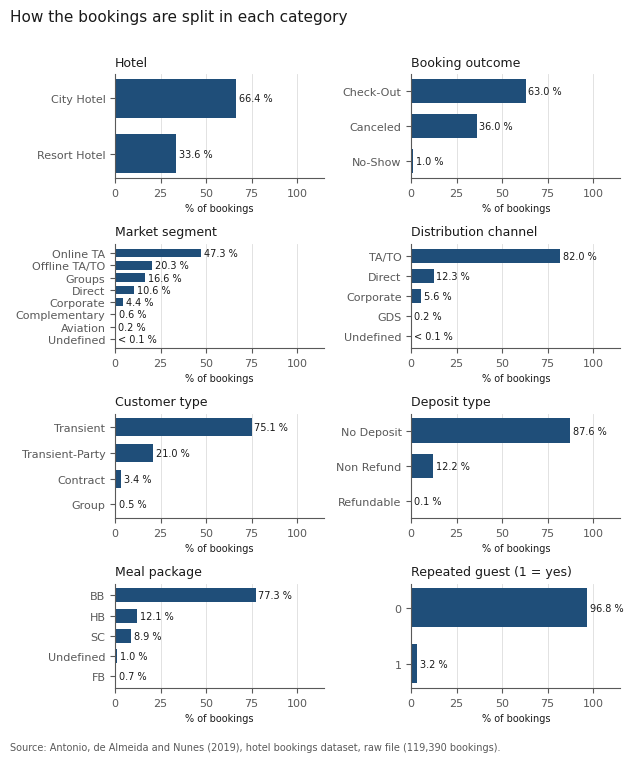

In [10]:
# ── Chart 4: small multiples of the categorical fields ───────────────────────

panel_titles = {
    'hotel': 'Hotel', 'reservation_status': 'Booking outcome',
    'market_segment': 'Market segment', 'distribution_channel': 'Distribution channel',
    'customer_type': 'Customer type', 'deposit_type': 'Deposit type',
    'meal': 'Meal package', 'is_repeated_guest': 'Repeated guest (1 = yes)',
}

fig, axes = plt.subplots(4, 2, figsize=(FIG_WIDTH, 7.6))
for ax, (field, title) in zip(axes.flatten(), panel_titles.items()):
    shares = category_shares[field].sort_values()          # largest bar at the top
    labels = [str(label) for label in shares.index]
    ax.barh(labels, shares.values, color=BAR_COLOR, height=0.7)
    for position, value in enumerate(shares.values):
        ax.text(value + 1.5, position, f'{value:.1f} %' if value >= 0.1 else '< 0.1 %', va='center', fontsize=7)
    ax.set_title(title, loc='left', fontsize=9)
    ax.set_xlim(0, 115)
    ax.set_xticks(range(0, 101, 25))
    ax.set_xlabel('% of bookings', fontsize=7)
    clean_axes(ax, 'x')

finish_figure(fig, 'How the bookings are split in each category', 'eda_categories.png')
plt.show()

**Comment:** the small multiples share one scale (0–100 % of bookings), so panels can be compared by position (Gestalt similarity and common scale). Most categorical fields are **dominated by one value** (`TA/TO` 82.0 %, `No Deposit` 87.6 %, `BB` 77.3 %, `Transient` 75.1 %), with several categories below 1 % (`Aviation`, `GDS`, `Refundable`, `Undefined`). For the dashboard this means that colour coding by these fields would show one big colour and several invisible ones; the small categories should be grouped into "Other" (the skills allow at most 7 colours).

### Chart 5: country of origin

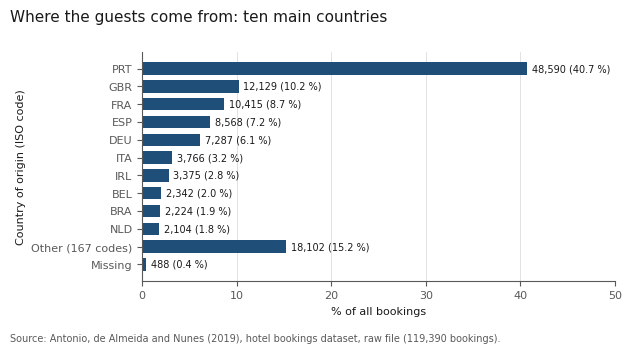

In [11]:
# ── Chart 5: top 10 countries, the rest and the missing ones ─────────────────

plot_table = country_table.iloc[::-1]          # largest at the top
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.4))
ax.barh(plot_table.index, plot_table['% of bookings'], color=BAR_COLOR, height=0.7)
for position, (count, share) in enumerate(zip(plot_table['bookings'], plot_table['% of bookings'])):
    ax.text(share + 0.5, position, f'{count:,} ({share:.1f} %)', va='center', fontsize=7)

ax.set_xlim(0, 50)
ax.set_xlabel('% of all bookings')
ax.set_ylabel('Country of origin (ISO code)')
clean_axes(ax, 'x')
finish_figure(fig, 'Where the guests come from: ten main countries', 'eda_countries.png')
plt.show()

**Comment:** the distribution of countries is very uneven. Portugal, the hotels' own country, is the largest group by far, followed by the United Kingdom, France, Spain and Germany; after the tenth country, the remaining 167 codes add up to only 15.2 % of the bookings, so most countries have very few guests. Codes are ISO abbreviations, so a dashboard would need country names (extra data, to be discussed in Part 3).

### Chart 6: count fields that are almost always zero

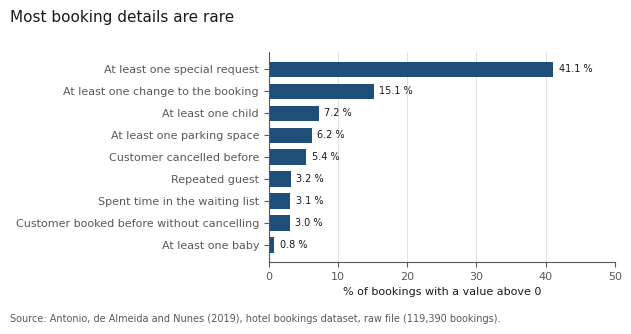

At least one baby                             0.8
Customer booked before without cancelling     3.0
Spent time in the waiting list                3.1
Repeated guest                                3.2
Customer cancelled before                     5.4
At least one parking space                    6.2
At least one child                            7.2
At least one change to the booking           15.1
At least one special request                 41.1
dtype: float64

In [12]:
# ── Chart 6: share of bookings with a value above 0 ──────────────────────────

count_fields = {
    'total_of_special_requests': 'At least one special request',
    'booking_changes': 'At least one change to the booking',
    'children': 'At least one child',
    'required_car_parking_spaces': 'At least one parking space',
    'previous_cancellations': 'Customer cancelled before',
    'is_repeated_guest': 'Repeated guest',
    'previous_bookings_not_canceled': 'Customer booked before without cancelling',
    'days_in_waiting_list': 'Spent time in the waiting list',
    'babies': 'At least one baby',
}
share_above_zero = pd.Series({label: 100 * (bookings[field] > 0).mean() for field, label in count_fields.items()}).sort_values()

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.2))
ax.barh(share_above_zero.index, share_above_zero.values, color=BAR_COLOR, height=0.7)
for position, value in enumerate(share_above_zero.values):
    ax.text(value + 0.8, position, f'{value:.1f} %', va='center', fontsize=7)
ax.set_xlim(0, 50)
ax.set_xlabel('% of bookings with a value above 0')
clean_axes(ax, 'x')
finish_figure(fig, 'Most booking details are rare', 'eda_rare_counts.png')
plt.show()

share_above_zero.round(1)

**Comment:** apart from special requests (41.1 % of bookings have at least one) and changes (15.1 %), these fields are 0 in more than nine bookings out of ten. Their distributions are a large spike at 0 and a thin tail, so for a dashboard they are best shown as **shares** ("3.2 % are repeated guests") rather than as averages, which would be close to 0 and hard to read.

## 6. Export

In [13]:
# ── Export ────────────────────────────────────────────────────────────────────
distribution_summary.to_csv(OUTPUT_DIR / 'distribution_summary.csv')
category_shares.to_csv(OUTPUT_DIR / 'category_shares.csv')
country_table.to_csv(OUTPUT_DIR / 'country_shares.csv')
share_above_zero.round(2).rename('% of bookings above 0').to_csv(OUTPUT_DIR / 'share_above_zero.csv')

sorted(p.name for p in OUTPUT_DIR.iterdir()) + sorted(p.name for p in IMAGES_DIR.glob('eda_*.png'))

['category_shares.csv',
 'country_shares.csv',
 'distribution_summary.csv',
 'share_above_zero.csv',
 'eda_adr_by_hotel.png',
 'eda_categories.png',
 'eda_countries.png',
 'eda_lead_time.png',
 'eda_rare_counts.png',
 'eda_total_nights.png']

## Conclusions

### Main findings
1. All numeric fields are **right-skewed**: lead time (median 69 days, up to 737), price per night and length of stay have long tails, so medians and ranges summarise them better than means.
2. Length of stay has **weekly peaks** (7 and 14 nights), a real pattern that bins would hide.
3. The Resort Hotel's prices vary much more than the City Hotel's, a first sign of seasonality.
4. Most categorical fields are dominated by one value, and many categories are below 1 %; countries are concentrated in Portugal and four European markets.
5. Many count fields are almost always 0; they are better shown as shares.

### Limitations
- The charts use the raw data, including duplicates and the odd values found in task 1.2; the numbers may change slightly after cleaning (task 1.6).
- The 1.5 × IQR rule is not meaningful for fields where Q1 = Q3.

### Suggested next steps
- Task 1.4: relationships between fields (time, hotel, segment, country, cancellations, price).